# KS1998 training ablation

## tl;dr

The largest controlled improvement in median held-out Euler error comes from increasing the optimization budget from 2,000 to 15,000 Adam updates. Extending simulated-state exposure also matters: at 2,000 updates, updating every other period instead of every period doubles the simulated path length and materially improves the median error. Small implementation changes—Fisher–Burmeister convention, Adam epsilon, output bounds, and whether the simulation advances with pre- or post-update parameters—have comparatively little effect.

At 15,000 updates, increasing the batch from 10 to 20 gives almost identical mean and median held-out Euler errors across two shock seeds, somewhat better p90 error and training loss, and at least 45% more measured runtime. Raising the household count from 50 to 100 does not improve Euler accuracy and costs about 2.4 times as much in the tested full-budget run. Keep `N=50, B=10` as the efficient reference default; treat `B=20` as a tail-accuracy option requiring learning-rate tuning.

## Context & Methods

The experiment uses the same Julia/Flux model and deterministic initialization as `notebooks/KS1998.ipynb`. Each comparison fixes the initialization seed and changes only the named setting. Held-out diagnostics use 64 conditional shock draws, and policy shape is evaluated on seven productivity slices with 100 wealth points.

### Key assumptions

- More negative `log10` Euler errors are better.
- Runtime is wall-clock CPU time measured inside training. The first configuration in each Julia process also bears some just-in-time compilation, so the measured batch-20 cost premium is conservative.
- Full-budget batch comparisons use two simulated shock paths. This is enough to expose seed sensitivity, but not to estimate tight sampling uncertainty.
- The household-count comparison has one full-budget seed because its computational cost is much higher.
- These results apply to the current raw full-distribution input, learning rate `1e-3`, and AiO loss; they are not a universal statement about batch-size scaling.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "experiments" / "results").exists():
    ROOT = ROOT.parent
RESULTS = ROOT / "experiments" / "results"

ablation = pd.read_csv(RESULTS / "ks1998_ablation.csv")
scaling = pd.read_csv(RESULTS / "ks1998_scaling.csv")
long_main = pd.read_csv(RESULTS / "ks1998_long.csv")
long_seed = pd.read_csv(RESULTS / "ks1998_long_seed_2027.csv")
old_comparison = pd.read_csv(RESULTS / "ks1998_old_comparison.csv")

assert len(ablation) == 6 and len(scaling) == 5
assert len(long_main) == 3 and len(long_seed) == 2 and len(old_comparison) == 3
assert np.isfinite(long_main.select_dtypes("number").to_numpy()).all()
print(f"Loaded four result files from {RESULTS}")

Loaded four result files from C:\Users\30945\Desktop\Yuxuan ZHAO\minnesota\Research\DeepLearningMacro\experiments\results


## Results

### 1. Small implementation choices at a fixed 2,000-update budget

In [2]:
ablation_view = ablation[[
    "name", "median_log10_euler", "p90_log10_euler",
    "mean_abs_fb", "monotonicity_violations", "seconds"
]].copy()
ablation_view.round({
    "median_log10_euler": 4,
    "p90_log10_euler": 4,
    "mean_abs_fb": 5,
    "seconds": 1,
})

,name,median_log10_euler,p90_log10_euler,mean_abs_fb,monotonicity_violations,seconds
0,reference_short,-1.8772,-1.4388,0.00401,15,43.6
1,paper_fb,-1.8767,-1.4313,0.00402,17,15.9
2,old_initialization,-1.8673,-1.4377,0.00398,0,15.7
3,post_update_advance,-1.8763,-1.4342,0.00387,14,17.8
4,adam_eps_1e-8,-1.8584,-1.4343,0.00410,15,15.6
5,old_output_bounds,-1.8822,-1.4360,0.00408,16,15.8


The held-out Euler metrics are tightly clustered. Initialization changes short-run policy shape, but it does not improve Euler accuracy. Monotonicity is therefore sensitive to optimization path and initialization; zero negative slopes should not be interpreted as an architectural guarantee.

### 2. Update frequency and the old high-dimensional configuration

In [3]:
old_view = old_comparison[[
    "name", "agents", "batch_size", "updates", "seconds",
    "median_log10_euler", "p90_log10_euler",
    "monotonicity_violations", "max_consumption"
]].copy()
old_view.round({
    "seconds": 1,
    "median_log10_euler": 4,
    "p90_log10_euler": 4,
    "max_consumption": 3,
})

,name,agents,batch_size,updates,seconds,median_log10_euler,p90_log10_euler,monotonicity_violations,max_consumption
0,reference_every_period,50,10,2000,40.1,-1.8053,-1.4104,17,3.072
1,old_bundle_N50_B10,50,10,2000,13.8,-1.8627,-1.4522,0,3.129
2,old_like_N200_B20,200,20,2000,370.0,-1.8272,-1.3778,0,3.090


With 2,000 updates, advancing the state for 4,000 periods (`update_every=2`) improves the reference-style median error from -1.805 to -1.877 relative to only 2,000 periods. The old-like `N=200, B=20` setup is less accurate than its `N=50, B=10` counterpart and is dramatically slower. The old-like label is deliberate: the historical notebook uses `1-xi` in its FB term, whereas this controlled runner uses the paper-style `1-c/w`; they differ when the capital cap binds.

### 3. Household and batch scaling at 2,000 updates

In [4]:
scaling_view = scaling[[
    "name", "parameters", "median_log10_euler", "p90_log10_euler",
    "monotonicity_violations", "seconds"
]].copy()
scaling_view.round({
    "median_log10_euler": 4,
    "p90_log10_euler": 4,
    "seconds": 1,
})

,name,parameters,median_log10_euler,p90_log10_euler,monotonicity_violations,seconds
0,N50_B10,4450,-1.8772,-1.4388,15,43.4
1,N50_B20,4450,-1.7738,-1.3393,35,27.8
2,N50_B40,4450,-1.7658,-1.2942,32,66.1
3,N100_B10,7650,-1.8339,-1.4257,0,46.4
4,N100_B20,7650,-1.8655,-1.4285,0,126.0


At a short fixed-update budget, larger batches converge more slowly under the unchanged learning rate. Increasing `N` to 100 removes negative slopes in this particular short run but does not improve held-out Euler accuracy.

### 4. Full 15,000-update comparisons

In [5]:
full_runs = pd.concat([
    long_main[long_main["name"].isin(["reference_15k", "N50_B20_15k"])],
    long_seed,
], ignore_index=True)

batch_summary = (
    full_runs.groupby("batch_size", as_index=False)
    .agg(
        seeds=("seed", "count"),
        seconds=("seconds", "mean"),
        mean_log10_euler=("mean_log10_euler", "mean"),
        median_log10_euler=("median_log10_euler", "mean"),
        p90_log10_euler=("p90_log10_euler", "mean"),
        mean_abs_fb=("mean_abs_fb", "mean"),
        tail_abs_loss=("tail_abs_loss", "mean"),
        monotonicity_violations=("monotonicity_violations", "max"),
    )
)
batch_summary.round({
    "seconds": 1,
    "mean_log10_euler": 4,
    "median_log10_euler": 4,
    "p90_log10_euler": 4,
    "mean_abs_fb": 5,
    "tail_abs_loss": 6,
})

,batch_size,seeds,seconds,mean_log10_euler,median_log10_euler,p90_log10_euler,mean_abs_fb,tail_abs_loss,monotonicity_violations
0,10,2,145.5,-2.0588,-1.9813,-1.4818,0.00466,0.000510,0
1,20,2,211.1,-2.0617,-1.9830,-1.5251,0.00394,0.000352,0


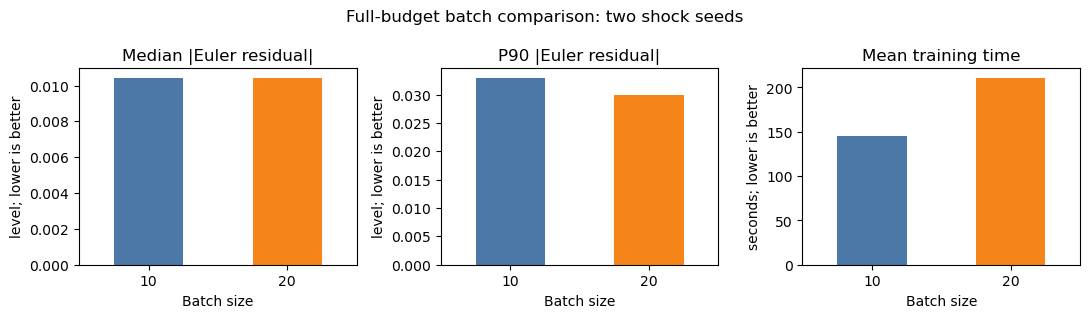

In [6]:
plot_data = batch_summary.set_index("batch_size")
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))

(10 ** plot_data["median_log10_euler"]).plot.bar(ax=axes[0], color=["#4C78A8", "#F58518"])
axes[0].set_title("Median |Euler residual|")
axes[0].set_xlabel("Batch size")
axes[0].set_ylabel("level; lower is better")
axes[0].tick_params(axis="x", rotation=0)

(10 ** plot_data["p90_log10_euler"]).plot.bar(ax=axes[1], color=["#4C78A8", "#F58518"])
axes[1].set_title("P90 |Euler residual|")
axes[1].set_xlabel("Batch size")
axes[1].set_ylabel("level; lower is better")
axes[1].tick_params(axis="x", rotation=0)

plot_data["seconds"].plot.bar(ax=axes[2], color=["#4C78A8", "#F58518"])
axes[2].set_title("Mean training time")
axes[2].set_xlabel("Batch size")
axes[2].set_ylabel("seconds; lower is better")
axes[2].tick_params(axis="x", rotation=0)

fig.suptitle("Full-budget batch comparison: two shock seeds")
fig.tight_layout()
plt.show()

In [7]:
household_comparison = long_main[[
    "name", "agents", "batch_size", "parameters", "seconds",
    "median_log10_euler", "p90_log10_euler", "mean_abs_fb",
    "monotonicity_violations", "mean_aggregate_k", "aggregation_r2"
]].copy()
household_comparison.round({
    "seconds": 1,
    "median_log10_euler": 4,
    "p90_log10_euler": 4,
    "mean_abs_fb": 5,
    "mean_aggregate_k": 4,
    "aggregation_r2": 4,
})

,name,agents,batch_size,parameters,seconds,median_log10_euler,p90_log10_euler,mean_abs_fb,monotonicity_violations,mean_aggregate_k,aggregation_r2
0,reference_15k,50,10,4450,145.4,-1.9622,-1.4287,0.00450,0,5.7651,0.9867
1,N50_B20_15k,50,20,4450,210.7,-1.9870,-1.5436,0.00417,0,5.4052,0.9834
2,N100_B10_15k,100,10,7650,348.8,-1.9575,-1.4472,0.00261,0,5.6226,0.9778


## Takeaways

1. **Optimization horizon is the largest controlled accuracy improvement.** With the reference setup, moving from 2,000 to 15,000 updates improves median `log10` Euler error from about -1.88 to -1.96. Doubling simulated-state exposure at a fixed 2,000 updates also improves the median from about -1.81 to -1.88.
2. **Shape improvement has multiple causes.** Long training removes negative slopes for the reference initialization, but the old initialization can also produce zero negative slopes after 2,000 updates. The plotted base cross section changes the visual slice as well. None of these settings guarantees monotonicity or concavity.
3. **Do not raise the household count by default.** `N=100, B=10` has essentially the same full-budget median Euler error as `N=50, B=10`, but increases parameters from 4,450 to 7,650 and runtime from about 145 to 349 seconds. The old-like `N=200, B=20` short run is also worse and exceptionally costly.
4. **Batch 20 is a defensible optional setting, not a robust dominance result.** Across two full-budget paths, its average mean/median Euler errors are essentially tied with batch 10, while average p90 error, FB residual, and tail loss are better. It costs at least 45% more in measured time, and the seed-by-seed Euler ranking reverses.
5. **Recommended default:** retain `N=50, B=10, 15,000 updates` for reference replication and efficiency. If tail residuals matter more than runtime, test `B=20` together with a learning-rate sweep rather than changing batch alone.

The raw result files and the Julia runner are in `experiments/results/` and `experiments/ks1998_ablation.jl`.